<a href="https://colab.research.google.com/github/Akash14-09/ML_Projects/blob/main/Assistive_Vision_01_Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



##Start here when you start a new session


###Run these three cells to store everything back


In [16]:
%pip install ultralytics==8.4.184

In [17]:
from google.colab import drive
from pathlib import Path
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

drive.mount("/content/drive")

project = Path("/content/drive/MyDrive/AssistiveVision")
model = YOLO(str(project / "models/yolov8n.pt"))

print("Project and model loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project and model loaded.


In [29]:
def describe_image(input_image, confidence=0.25):
    result = model.predict(
        source=input_image,
        conf=confidence,
        verbose=False
    )[0]

    width, _ = input_image.size
    observations = []

    for box in result.boxes:
        label = model.names[int(box.cls.item())]
        score = float(box.conf.item())
        coordinates = box.xyxy[0].tolist()

        # Use our improved position description.
        position = describe_position(coordinates, width)

        observations.append({
            "label": label,
            "score": score,
            "position": position,
            "box": coordinates
        })

    phrases = [
        f"{item['label']} {item['position']}"
        for item in observations
    ]

    description = (
        "; ".join(phrases) + "."
        if phrases
        else "No supported objects detected."
    )

    return result, observations, description

In [1]:
import sys
import platform

print("Python version:", sys.version)
print("Operating system:", platform.system())

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Operating system: Linux


Saving bicycle-6580288_1280.jpg to bicycle-6580288_1280.jpg
File: bicycle-6580288_1280.jpg
Image dimensions: (853, 1280)


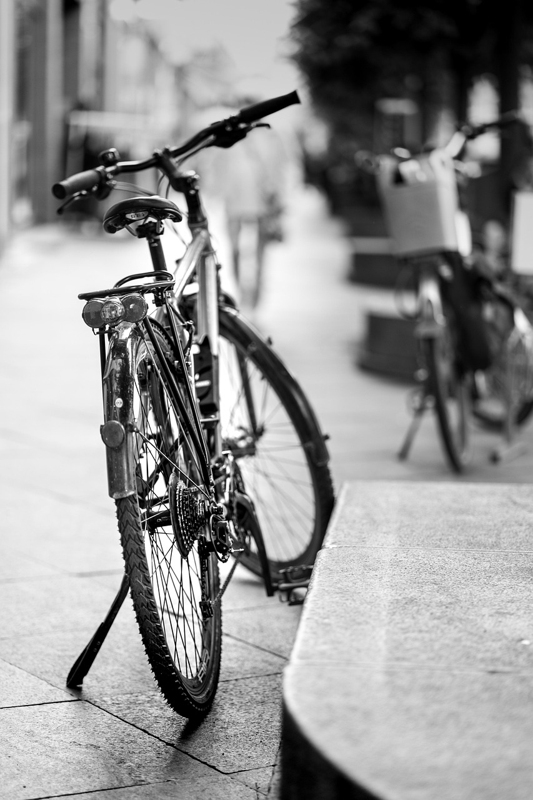

In [2]:
from google.colab import files
from PIL import Image
from IPython.display import display
import io

# Choose one image from your computer.
uploaded = files.upload()

# Read the uploaded file as an RGB image.
image_name = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[image_name])).convert("RGB")

print("File:", image_name)
print("Image dimensions:", image.size)

# Display a smaller preview without changing the original image.
preview = image.copy()
preview.thumbnail((800, 800))
display(preview)

In [3]:
%pip install ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 5.6 MB/s eta 0:00:00


In [4]:
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("Ready to load an object-detection model.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.184
Ready to load an object-detection model.


In [5]:
# Load pretrained YOLOv8 Nano weights.
# The weights download automatically the first time.
model = YOLO("yolov8n.pt")

print("Model loaded successfully.")
print("Number of object classes:", len(model.names))
print("Recognises bicycle:", "bicycle" in model.names.values())


Model loaded successfully.
Number of object classes: 80
Recognises bicycle: True


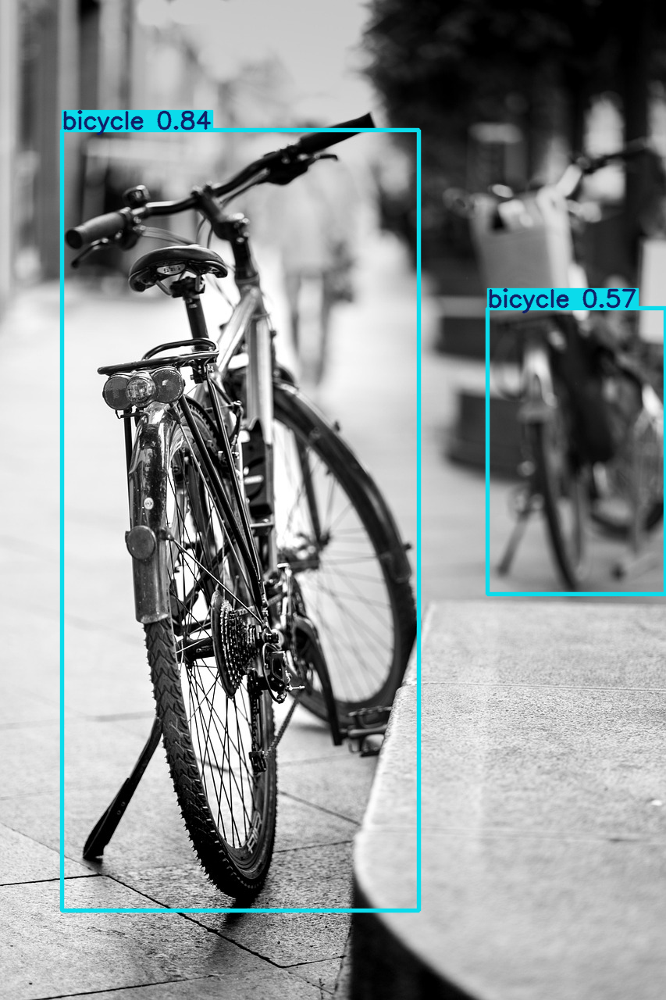

In [6]:
# Predict objects in the PIL image we uploaded earlier.
results = model.predict(source=image, conf=0.25, verbose=False)

# We supplied one image, so take its result.
result = results[0]

# Draw predicted boxes, labels, and scores.
# plot() returns BGR pixels; convert to RGB for correct display.
annotated_image = Image.fromarray(result.plot()[:, :, ::-1])
display(annotated_image)

In [7]:
if len(result.boxes) == 0:
    print("No objects detected above the chosen confidence threshold.")
else:
    for box in result.boxes:
        class_id = int(box.cls.item())
        label = model.names[class_id]
        score = float(box.conf.item())
        coordinates = box.xyxy[0].tolist()

        print(f"Object: {label}")
        print(f"Confidence score: {score:.3f}")
        print(f"Box [x1, y1, x2, y2]: {[round(v) for v in coordinates]}")
        print()

Object: bicycle
Confidence score: 0.838
Box [x1, y1, x2, y2]: [80, 167, 537, 1165]

Object: bicycle
Confidence score: 0.575
Box [x1, y1, x2, y2]: [624, 395, 853, 761]



Saving Screenshot 2026-10-23 185900.png to Screenshot 2026-10-23 185900.png


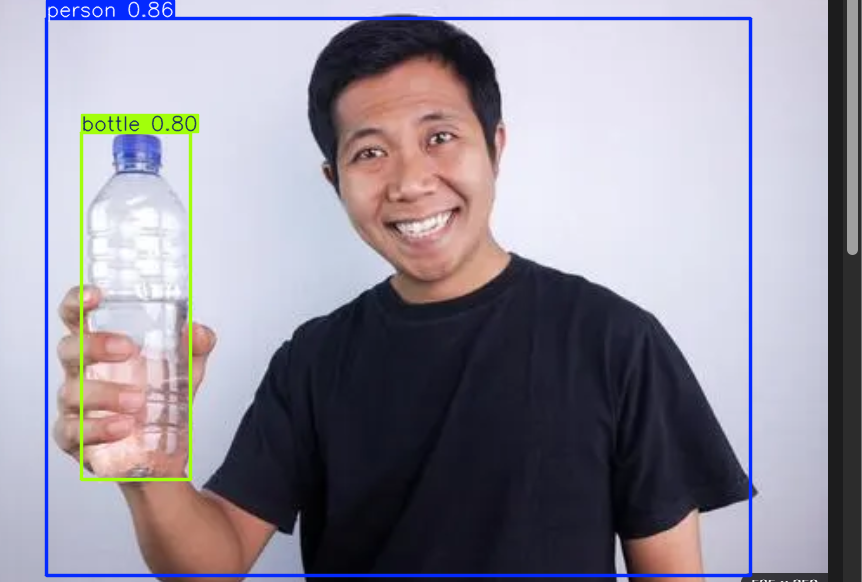

person: 0.865
bottle: 0.798


In [10]:
# Upload a new test image.
uploaded_test = files.upload()
test_name = next(iter(uploaded_test))

test_image = Image.open(
    io.BytesIO(uploaded_test[test_name])
).convert("RGB")

# Use the same model and confidence threshold.
test_result = model.predict(
    source=test_image,
    conf=0.25,
    verbose=False
)[0]

display(Image.fromarray(test_result.plot()[:, :, ::-1]))

# List all detections, including people if present.
for box in test_result.boxes:
    label = model.names[int(box.cls.item())]
    score = float(box.conf.item())
    print(f"{label}: {score:.3f}")

if len(test_result.boxes) == 0:
    print("No detections above 0.25.")

In [11]:
image_width, image_height = test_image.size
observations = []

for box in test_result.boxes:
    label = model.names[int(box.cls.item())]
    score = float(box.conf.item())

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    # Centre of the bounding box, expressed as a fraction of image width.
    centre_x = (x1 + x2) / 2
    relative_x = centre_x / image_width

    if relative_x < 1 / 3:
        position = "left"
    elif relative_x < 2 / 3:
        position = "centre"
    else:
        position = "right"

    observations.append({
        "object": label,
        "score": score,
        "position": position
    })

    print(f"{label}: {position} | score={score:.3f}")

# Include every detection rather than only the highest-scoring one.
phrases = [
    f"{item['object']} {'in the centre' if item['position'] == 'centre' else 'on the ' + item['position']}"
    for item in observations
]

description = (
    "; ".join(phrases) + "."
    if phrases
    else "No supported objects detected."
)

print("\nDescription:", description)

person: centre | score=0.865
bottle: left | score=0.798

Description: person in the centre; bottle on the left.


In [12]:
def describe_image(input_image, confidence=0.25):
    result = model.predict(
        source=input_image,
        conf=confidence,
        verbose=False
    )[0]

    width, _ = input_image.size
    observations = []

    for box in result.boxes:
        label = model.names[int(box.cls.item())]
        score = float(box.conf.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        relative_x = ((x1 + x2) / 2) / width

        if relative_x < 1 / 3:
            position = "on the left"
        elif relative_x < 2 / 3:
            position = "in the centre"
        else:
            position = "on the right"

        observations.append({
            "label": label,
            "score": score,
            "position": position
        })

    phrases = [
        f"{item['label']} {item['position']}"
        for item in observations
    ]

    description = (
        "; ".join(phrases) + "."
        if phrases
        else "No supported objects detected."
    )

    return result, observations, description

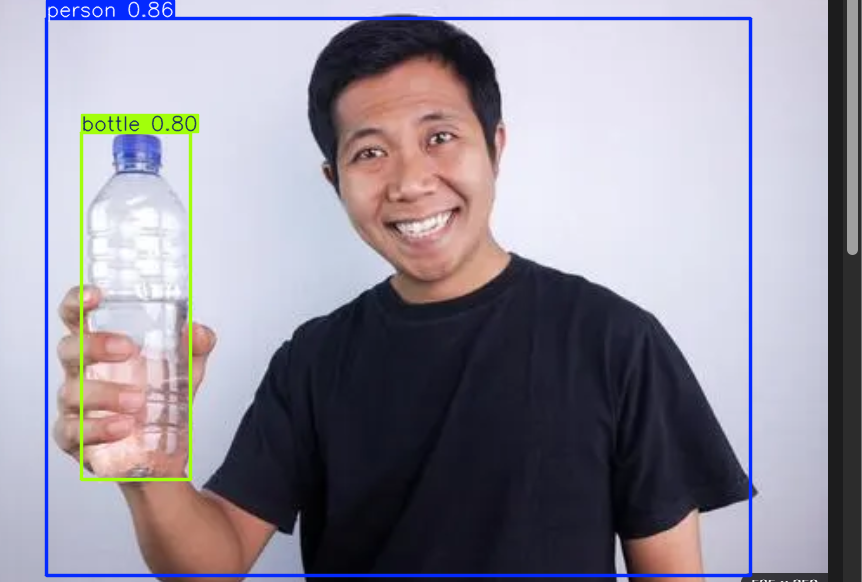

person in the centre; bottle on the left.


In [13]:
result, observations, description = describe_image(test_image)

display(Image.fromarray(result.plot()[:, :, ::-1]))
print(description)

In [14]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [15]:
from pathlib import Path
import shutil
import json

project = Path("/content/drive/MyDrive/AssistiveVision")

for folder in ["images", "models", "results"]:
    (project / folder).mkdir(parents=True, exist_ok=True)

# Save the current bottle test image.
test_image.save(project / "images/bottle_test.png")

# Preserve the downloaded pretrained weights.
weights = Path("/content/yolov8n.pt")
if weights.exists():
    shutil.copy2(weights, project / "models/yolov8n.pt")

# Save predictions and the description from our latest experiment.
saved_result = {
    "image": "bottle_test.png",
    "model": "yolov8n.pt",
    "confidence_threshold": 0.25,
    "observations": observations,
    "description": description,
}

(project / "results/bottle_test.json").write_text(
    json.dumps(saved_result, indent=2),
    encoding="utf-8"
)

print("Saved project files to:", project)

Saved project files to: /content/drive/MyDrive/AssistiveVision


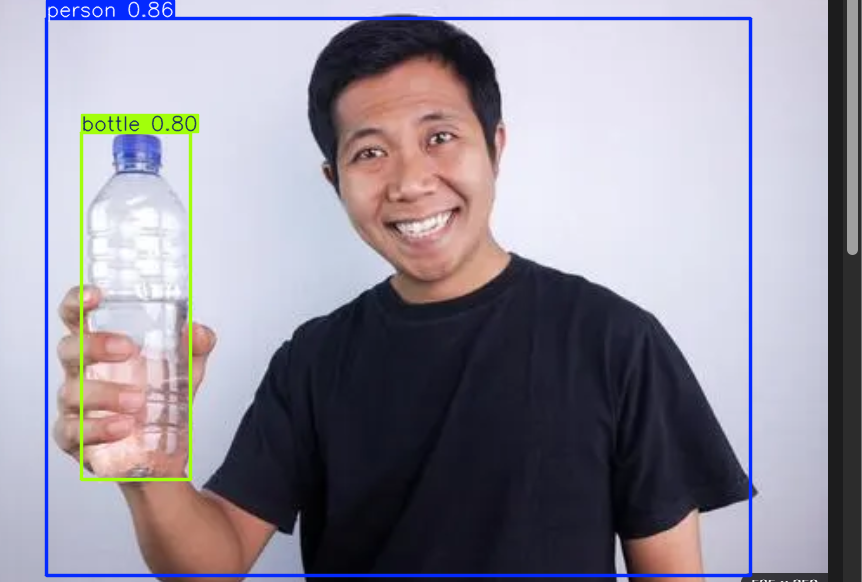

person in the centre; bottle on the left.


In [19]:
# Load our saved image without uploading it again.
test_image = Image.open(
    project / "images/bottle_test.png"
).convert("RGB")

result, observations, description = describe_image(test_image)

display(Image.fromarray(result.plot()[:, :, ::-1]))
print(description)

In [20]:
!apt-get -qq update && apt-get -qq install -y espeak

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libportaudio2:amd64.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../libportaudio2_19.6.0-1.2build3_amd64.deb ...
Unpacking libportaudio2:amd64 (19.6.0-1.2build3) ...
Selecting previously unselected package libsonic0:amd64.
Preparing to unpack .../libsonic0_0.2.0-13build1_amd64.deb ...
Unpacking libsonic0:amd64 (0.2.0-13build1) ...
Selecting previously unselected package espeak-data:amd64.
Preparing to unpack .../espeak-data_1.48.15+dfsg-3build1_amd64.deb ...
Unpacking espeak-data:amd64 (1.48.15+dfsg-3build1) ...
Selecting previously unselected package libespeak1:amd64.
Preparing to unpack .../libespeak1_1.48.15+dfsg-3build1_amd64.deb ...
Unpacking libespeak1:amd64 (1.48.15+dfsg-3build1) ...
Selecting previously 

In [21]:
import subprocess
from IPython.display import Audio, display

audio_path = project / "results/description.wav"

subprocess.run(
    [
        "espeak",
        "-v", "en",              # English voice
        "-s", "150",             # Speaking speed
        "-w", str(audio_path),   # Save audio as a WAV file
        "--stdin"
    ],
    input=description,
    text=True,
    check=True
)

print("Description:", description)
display(Audio(filename=str(audio_path)))

Description: person in the centre; bottle on the left.


In [23]:
#categories that the model show
print(", ".join(model.names.values()))

person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign, parking meter, bench, bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe, backpack, umbrella, handbag, tie, suitcase, frisbee, skis, snowboard, sports ball, kite, baseball bat, baseball glove, skateboard, surfboard, tennis racket, bottle, wine glass, cup, fork, knife, spoon, bowl, banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake, chair, couch, potted plant, bed, dining table, toilet, tv, laptop, mouse, remote, keyboard, cell phone, microwave, oven, toaster, sink, refrigerator, book, clock, vase, scissors, teddy bear, hair drier, toothbrush


In [24]:
from google.colab import files

uploaded_tests = files.upload()

test_folder = project / "images" / "evaluation"
test_folder.mkdir(parents=True, exist_ok=True)

for name, content in uploaded_tests.items():
    # Keep only the filename when constructing the destination.
    destination = test_folder / Path(name).name
    destination.write_bytes(content)

print(f"Saved {len(uploaded_tests)} files.")

Saving Screenshot 2026-10-23 185426.png to Screenshot 2026-10-23 185426.png
Saving Screenshot 2026-10-23 185538.png to Screenshot 2026-10-23 185538 (1).png
Saving Screenshot 2026-10-23 185711.png to Screenshot 2026-10-23 185711 (1).png
Saving Screenshot 2026-10-23 185936.png to Screenshot 2026-10-23 185936.png
Saving Screenshot 2026-10-23 191813.png to Screenshot 2026-10-23 191813.png
Saving Screenshot 2026-10-23 195547.png to Screenshot 2026-10-23 195547.png
Saved 6 files.



IMAGE: Screenshot 2026-10-23 185426.png
DESCRIPTION: bicycle in the centre; bicycle on the right.


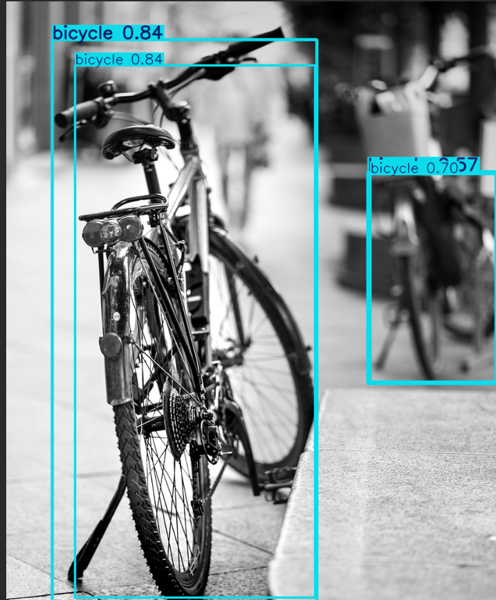


IMAGE: Screenshot 2026-10-23 185538 (1).png
DESCRIPTION: vase in the centre.


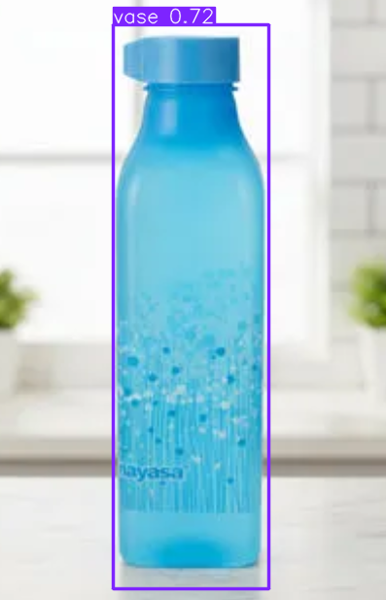


IMAGE: Screenshot 2026-10-23 185711 (1).png
DESCRIPTION: person in the centre.


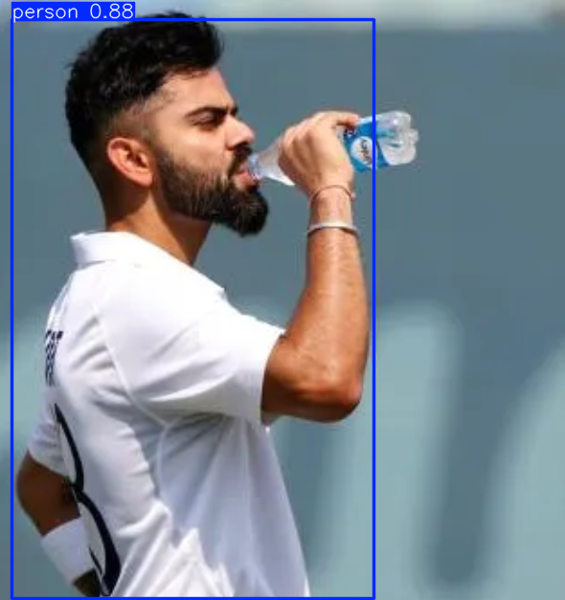


IMAGE: Screenshot 2026-10-23 185936.png
DESCRIPTION: person in the centre; bottle on the left.


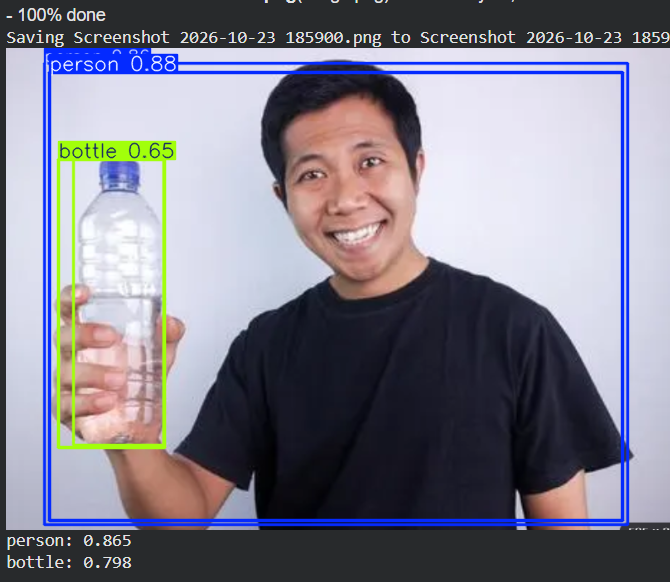


IMAGE: Screenshot 2026-10-23 191813.png
DESCRIPTION: bottle on the right; bottle on the right; bowl on the right; clock on the left; clock in the centre.


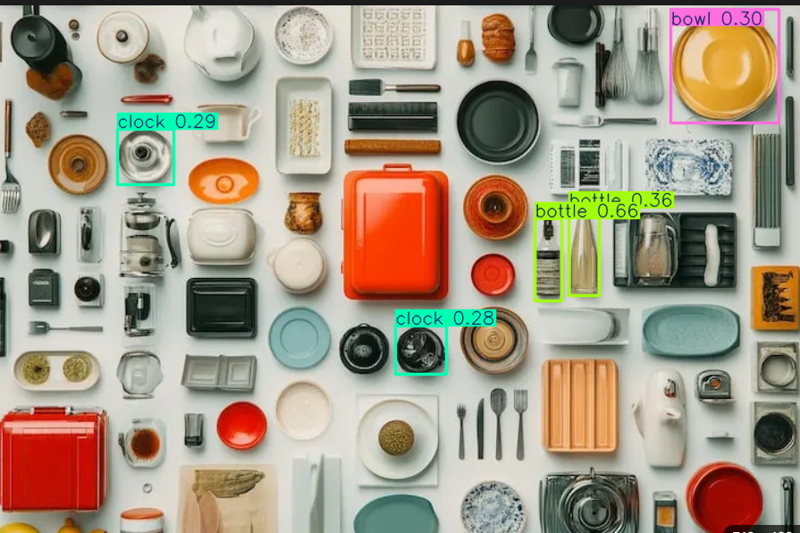


IMAGE: Screenshot 2026-10-23 195547.png
DESCRIPTION: bed in the centre; potted plant in the centre; tv in the centre.


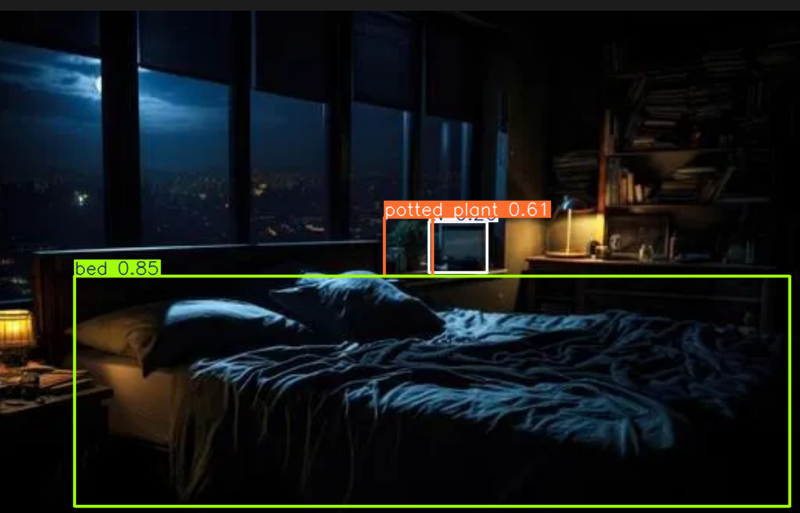

In [25]:
for image_path in sorted(test_folder.iterdir()):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue

    with Image.open(image_path) as source:
        evaluation_image = source.convert("RGB")

    result, observations, description = describe_image(evaluation_image)

    print(f"\nIMAGE: {image_path.name}")
    print("DESCRIPTION:", description)

    annotated = Image.fromarray(result.plot()[:, :, ::-1])
    annotated.thumbnail((800, 600))
    display(annotated)

Inspecting: Screenshot 2026-10-23 195547.png
bed: midpoint at 54% of image width; box spans 9%–99%
potted plant: midpoint at 51% of image width; box spans 48%–54%
tv: midpoint at 57% of image width; box spans 54%–61%


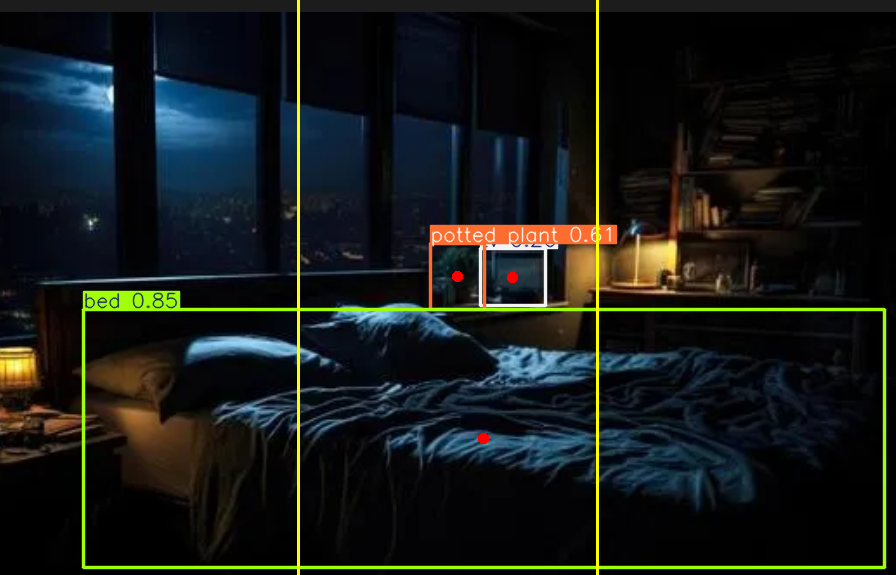

In [34]:
from PIL import ImageDraw

print("Inspecting:", image_path.name)

# Start with the model's existing boxes and labels.
debug_image = Image.fromarray(result.plot()[:, :, ::-1])
draw = ImageDraw.Draw(debug_image)

width, height = evaluation_image.size

# Show the exact boundaries used by our current position rule.
for boundary in (width / 3, 2 * width / 3):
    draw.line(
        [(int(boundary), 0), (int(boundary), height)],
        fill="yellow",
        width=3
    )

for box in result.boxes:
    label = model.names[int(box.cls.item())]
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    centre_x = (x1 + x2) / 2
    centre_y = (y1 + y2) / 2

    # Mark the point our position rule actually uses.
    radius = 5
    draw.ellipse(
        [
            centre_x - radius, centre_y - radius,
            centre_x + radius, centre_y + radius
        ],
        fill="red"
    )

    print(
        f"{label}: "
        f"midpoint at {centre_x / width:.0%} of image width; "
        f"box spans {x1 / width:.0%}–{x2 / width:.0%}"
    )

debug_image.thumbnail((1000, 750))
display(debug_image)

In [35]:
def describe_position(box, image_width):
    x1, y1, x2, y2 = box

    left = x1 / image_width
    right = x2 / image_width
    centre = (left + right) / 2

    # A box extending across most of the image needs different wording.
    if left <= 0.20 and right >= 0.80:
        return "spanning most of the view"

    if centre < 0.30:
        return "on the left"
    elif centre < 0.45:
        return "slightly left of centre"
    elif centre <= 0.55:
        return "near the centre"
    elif centre <= 0.70:
        return "slightly right of centre"
    else:
        return "on the right"

In [36]:
width, _ = evaluation_image.size

for box in result.boxes:
    label = model.names[int(box.cls.item())]
    coordinates = box.xyxy[0].tolist()

    position = describe_position(coordinates, width)
    print(f"{label.capitalize()} {position}.")

Bed spanning most of the view.
Potted plant near the centre.
Tv slightly right of centre.


In [37]:
def describe_image(input_image, confidence=0.25):
    result = model.predict(
        source=input_image,
        conf=confidence,
        verbose=False
    )[0]

    width, _ = input_image.size
    observations = []

    for box in result.boxes:
        label = model.names[int(box.cls.item())]
        score = float(box.conf.item())
        coordinates = box.xyxy[0].tolist()

        # Use our improved position description.
        position = describe_position(coordinates, width)

        observations.append({
            "label": label,
            "score": score,
            "position": position,
            "box": coordinates
        })

    phrases = [
        f"{item['label']} {item['position']}"
        for item in observations
    ]

    description = (
        "; ".join(phrases) + "."
        if phrases
        else "No supported objects detected."
    )

    return result, observations, description

Updated description:
bed spanning most of the view; potted plant near the centre; tv slightly right of centre.


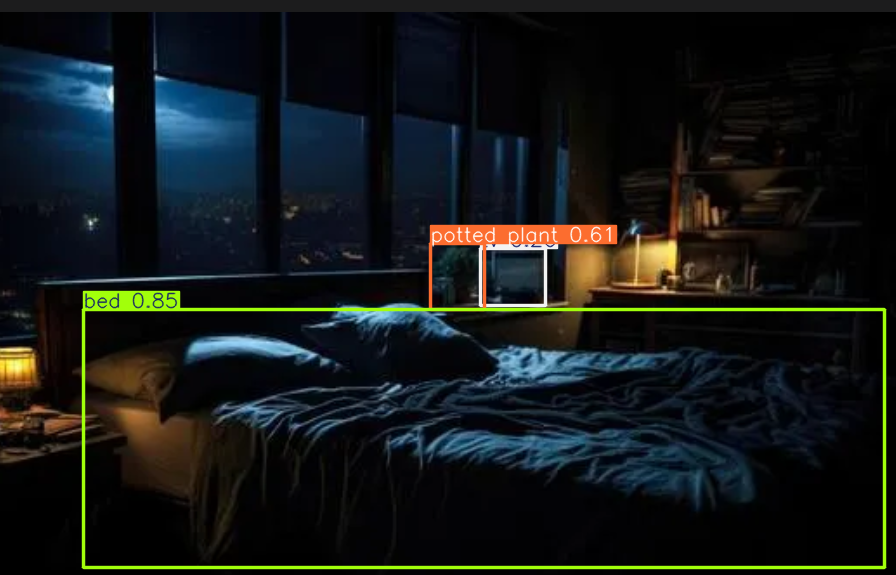

In [38]:
result, observations, description = describe_image(evaluation_image)

print("Updated description:")
print(description)

display(Image.fromarray(result.plot()[:, :, ::-1]))


INPUT SIZE: 640
Detections: 5
  bottle: 0.66
  bottle: 0.36
  bowl: 0.30
  clock: 0.29
  clock: 0.28


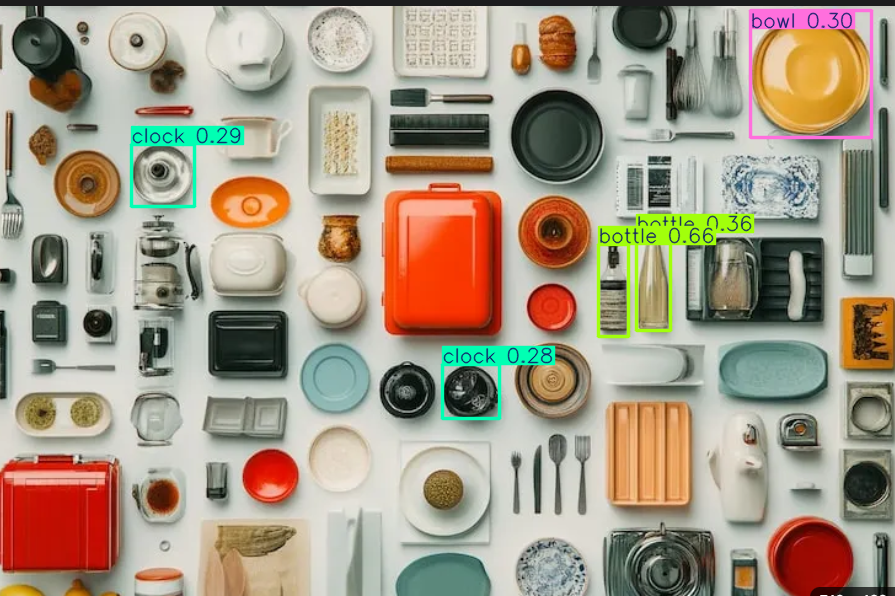


INPUT SIZE: 1280
Detections: 14
  bottle: 0.80
  spoon: 0.72
  microwave: 0.69
  bottle: 0.64
  keyboard: 0.63
  microwave: 0.58
  spoon: 0.56
  microwave: 0.44
  clock: 0.42
  cup: 0.37
  bowl: 0.29
  bowl: 0.28
  knife: 0.28
  bowl: 0.27


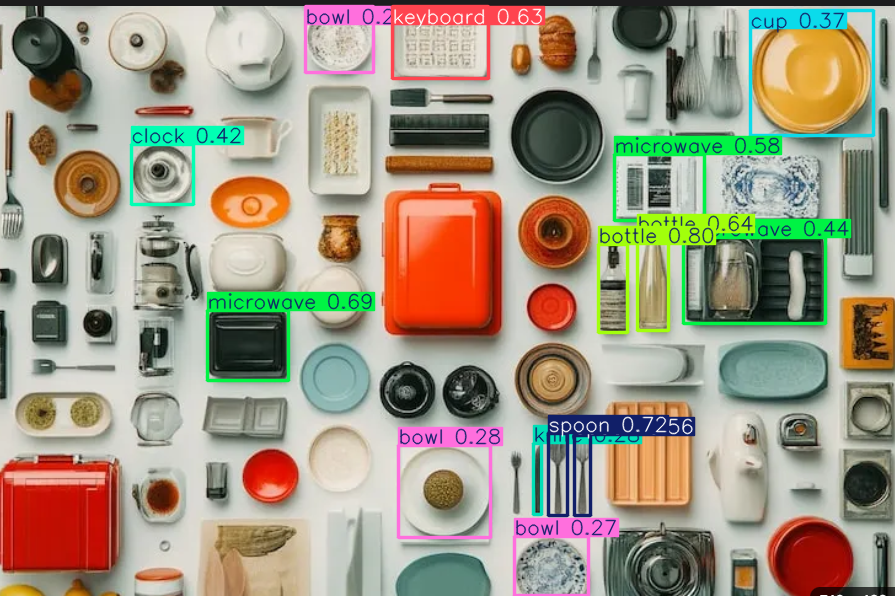

In [39]:
# Load the kitchen image saved earlier.
kitchen_path = (
    project / "images" / "evaluation"
    / "Screenshot 2026-10-23 191813.png"
)

kitchen_image = Image.open(kitchen_path).convert("RGB")

comparison_results = {}

for size in [640, 1280]:
    prediction = model.predict(
        source=kitchen_image,
        imgsz=size,
        conf=0.25,
        verbose=False
    )[0]

    comparison_results[size] = prediction

    print(f"\nINPUT SIZE: {size}")
    print(f"Detections: {len(prediction.boxes)}")

    for box in prediction.boxes:
        label = model.names[int(box.cls.item())]
        score = float(box.conf.item())
        print(f"  {label}: {score:.2f}")

    preview = Image.fromarray(prediction.plot()[:, :, ::-1])
    preview.thumbnail((900, 900))
    display(preview)

Saving video_for_dl_project.mp4 to video_for_dl_project.mp4
FPS: 29.89
Frames: 327
Approximate duration: 10.9 seconds


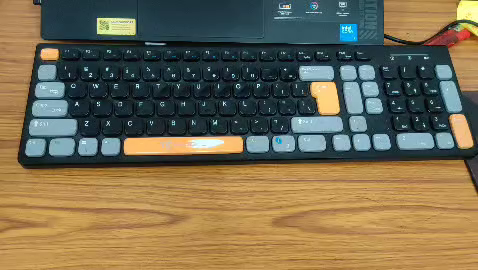

In [40]:
from google.colab import files
import cv2
import shutil

uploaded_video = files.upload()
video_name = next(iter(uploaded_video))

video_folder = project / "videos"
video_folder.mkdir(parents=True, exist_ok=True)

video_path = video_folder / Path(video_name).name
shutil.copy2(video_name, video_path)

# Release the uploaded bytes from Python memory.
del uploaded_video

cap = cv2.VideoCapture(str(video_path))

try:
    if not cap.isOpened():
        raise ValueError("Could not open this video. Try an MP4 file.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"FPS: {fps:.2f}")
    print(f"Frames: {frame_count}")
    if fps > 0:
        print(f"Approximate duration: {frame_count / fps:.1f} seconds")

    success, frame = cap.read()
    if not success:
        raise ValueError("The video opened, but its first frame could not be read.")

    # OpenCV uses BGR; PIL expects RGB.
    first_frame = Image.fromarray(
        cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    )
    display(first_frame)

finally:
    cap.release()


At 0.0 seconds: keyboard spanning most of the view.


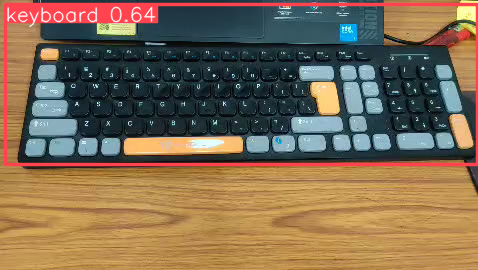


At 0.5 seconds: keyboard spanning most of the view.


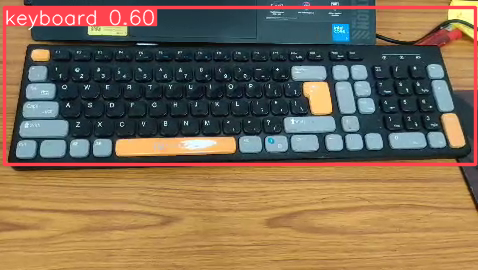


At 1.0 seconds: keyboard spanning most of the view; mouse on the right; laptop spanning most of the view.


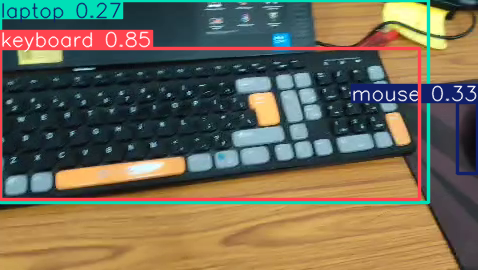


At 1.5 seconds: keyboard slightly left of centre; mouse on the right; laptop slightly left of centre.


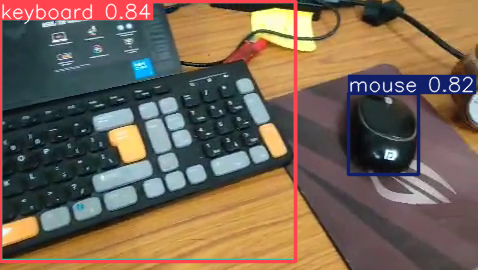


At 2.0 seconds: clock on the right; keyboard on the left; mouse slightly right of centre; laptop on the left; keyboard on the left.


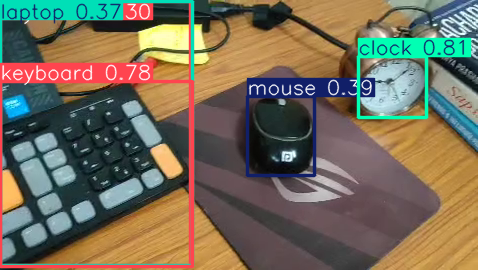


At 2.5 seconds: keyboard on the left; clock slightly right of centre; mouse slightly left of centre; book on the right.


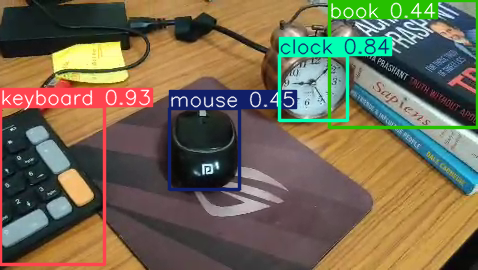


At 3.0 seconds: keyboard on the left; clock slightly right of centre; book on the right; mouse slightly left of centre; cup slightly left of centre.


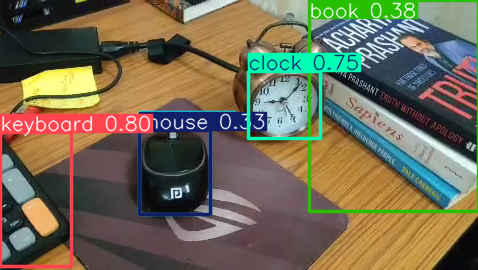


At 3.5 seconds: clock slightly right of centre; book on the right; book slightly left of centre.


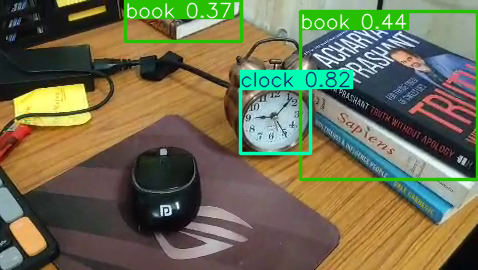


At 4.0 seconds: clock near the centre; book on the right; book on the right.


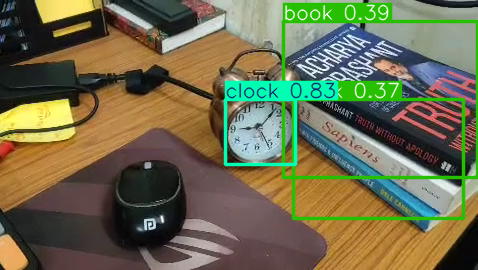


At 4.5 seconds: clock slightly left of centre; cup on the left; book slightly right of centre; mouse on the left; book on the right; book on the left.


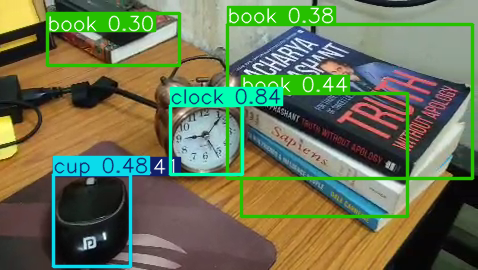


At 5.0 seconds: clock slightly left of centre; book slightly right of centre; book slightly right of centre; book on the left; book slightly right of centre; book slightly right of centre; book on the left; book slightly right of centre.


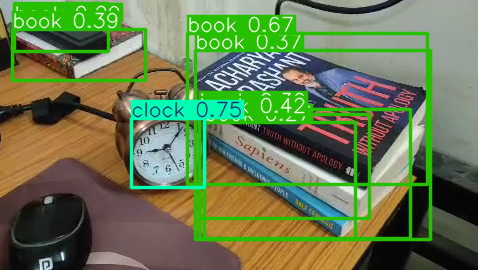


At 5.5 seconds: clock slightly left of centre; mouse on the left; book slightly right of centre; book on the left; book slightly right of centre.


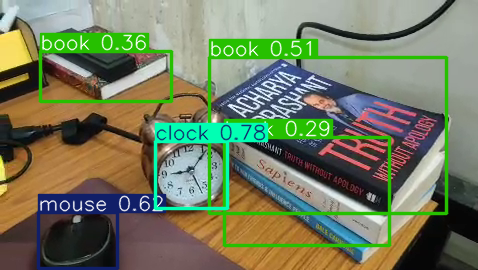


At 6.0 seconds: clock slightly right of centre; book on the right; chair on the right; book slightly left of centre.


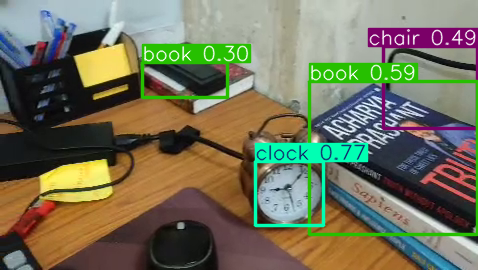


At 6.5 seconds: clock on the right; book near the centre; book on the right.


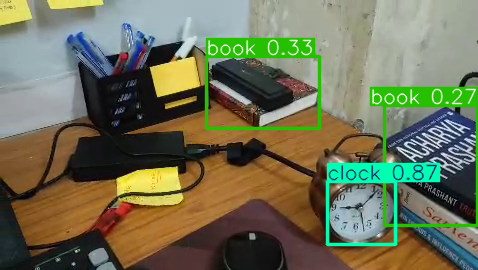


At 7.0 seconds: clock on the right; laptop on the left; keyboard on the left; tv slightly left of centre.


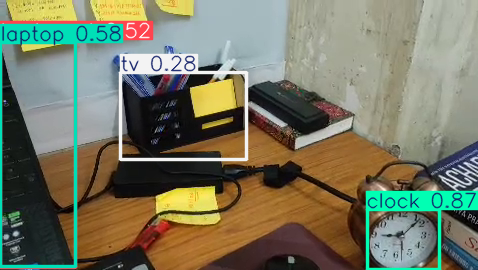


At 7.5 seconds: laptop on the left.


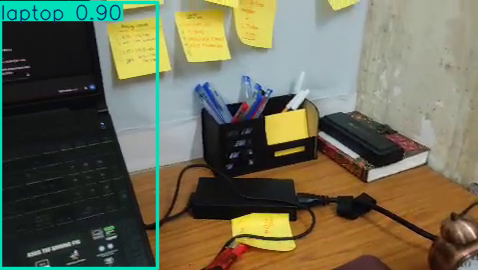


At 8.0 seconds: laptop on the left.


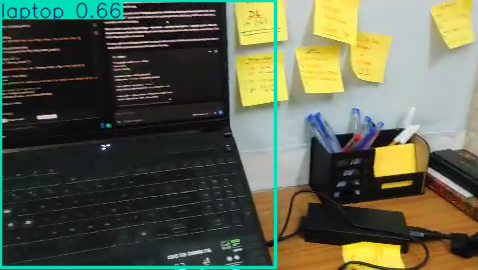


At 8.5 seconds: laptop slightly left of centre.


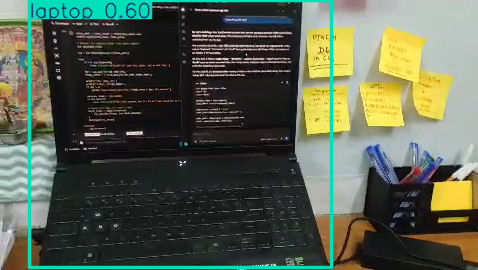


At 9.0 seconds: laptop slightly left of centre; book on the right.


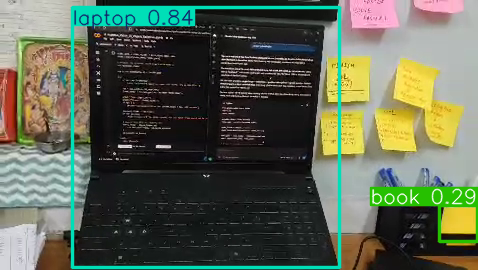


At 9.5 seconds: book on the left; laptop near the centre.


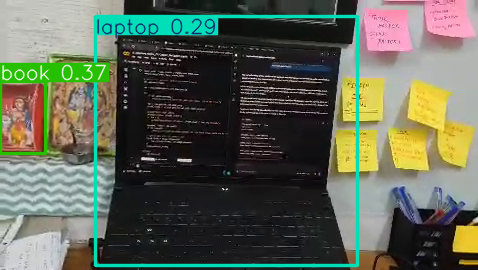


At 10.0 seconds: tv near the centre.


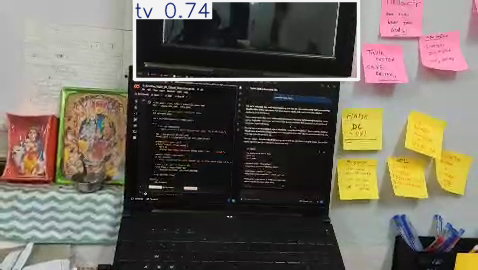


At 10.5 seconds: tv near the centre; person slightly left of centre.


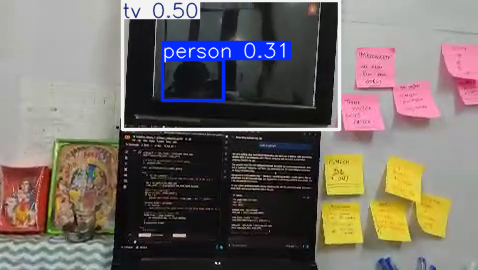

In [41]:
import cv2

cap = cv2.VideoCapture(str(video_path))
video_observations = []

try:
    if not cap.isOpened():
        raise ValueError("Could not open the video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        raise ValueError("Could not determine the video's frame rate.")

    # For example, at 30 FPS, analyse every 15th frame.
    sample_every = max(1, round(fps * 0.5))
    frame_index = 0

    while True:
        success, frame = cap.read()
        if not success:
            break

        if frame_index % sample_every == 0:
            timestamp = frame_index / fps

            frame_image = Image.fromarray(
                cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            )

            # Uses our existing model and position-description function.
            result, observations, description = describe_image(frame_image)

            video_observations.append({
                "time_seconds": round(timestamp, 2),
                "observations": observations,
                "description": description
            })

            print(f"\nAt {timestamp:.1f} seconds: {description}")

            preview = Image.fromarray(result.plot()[:, :, ::-1])
            preview.thumbnail((640, 480))
            display(preview)

        frame_index += 1

finally:
    cap.release()

In [42]:
import json

results_path = project / "results" / f"{video_path.stem}_observations.json"

results_path.write_text(
    json.dumps(video_observations, indent=2),
    encoding="utf-8"
)

print("Saved:", results_path)

Saved: /content/drive/MyDrive/AssistiveVision/results/video_for_dl_project_observations.json


In [45]:
def scene_key(observations):
    # Ignore confidence changes and detection order.
    # For now, describe each object type and position once.
    return tuple(sorted({
        (item["label"], item["position"])
        for item in observations
    }))


selected_messages = []
candidate = None
consecutive_matches = 0
last_announced_scene = None
last_announcement_time = float("-inf")

for entry in video_observations:
    current_scene = scene_key(entry["observations"])
    timestamp = entry["time_seconds"]

    if current_scene == candidate:
        consecutive_matches += 1
    else:
        candidate = current_scene
        consecutive_matches = 1

    # Require the same scene in two consecutive sampled frames.
    stable = consecutive_matches >= 2
    changed = current_scene != last_announced_scene
    enough_time = timestamp - last_announcement_time >= 4

    if stable and changed and enough_time:
        if current_scene:
            message = ". ".join(
                f"{label.capitalize()} {position}"
                for label, position in current_scene
            ) + "."
        else:
            message = "No supported objects detected."

        selected_messages.append(message)
        last_announced_scene = current_scene
        last_announcement_time = timestamp

        print(f"{timestamp:.1f}s: {message}")

0.5s: Keyboard spanning most of the view.
8.0s: Laptop on the left.


In [48]:
import subprocess
import tempfile
import wave
from pathlib import Path
from IPython.display import Audio, display

audio_path = project / "results" / "stable_narration.wav"

if not selected_messages:
    print("No stable descriptions found in this video.")
else:
    with tempfile.TemporaryDirectory() as temporary_folder:
        with wave.open(str(audio_path), "wb") as combined:
            audio_format = None

            for index, message in enumerate(selected_messages):
                clip_path = Path(temporary_folder) / f"message_{index}.wav"

                subprocess.run(
                    [
                        "espeak", "-v", "en", "-s", "140",
                        "-w", str(clip_path), "--stdin"
                    ],
                    input=message,
                    text=True,
                    check=True
                )

                with wave.open(str(clip_path), "rb") as clip:
                    current_format = (
                        clip.getnchannels(),
                        clip.getsampwidth(),
                        clip.getframerate()
                    )

                    if audio_format is None:
                        audio_format = current_format
                        combined.setnchannels(audio_format[0])
                        combined.setsampwidth(audio_format[1])
                        combined.setframerate(audio_format[2])

                    if current_format != audio_format:
                        raise ValueError("Audio formats do not match.")

                    # Write the entire message before adding the next one.
                    combined.writeframes(
                        clip.readframes(clip.getnframes())
                    )

                    # Add a short pause between scene descriptions.
                    channels, sample_width, sample_rate = audio_format
                    silence = b"\x00" * (
                        int(sample_rate * 0.8) * channels * sample_width
                    )
                    combined.writeframes(silence)

    display(Audio(filename=str(audio_path)))

In [49]:
%pip install -q "transformers>=4.49,<5" accelerate num2words

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 53.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [50]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

vlm_id = "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

processor = AutoProcessor.from_pretrained(vlm_id)

scene_model = AutoModelForImageTextToText.from_pretrained(
    vlm_id,
    torch_dtype=dtype,
    attn_implementation="sdpa"
).to(device)

scene_model.eval()

print("Scene model loaded on:", device)

processor_config.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/430 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.03G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

Scene model loaded on: cpu


In [52]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

vlm_id = "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

processor = AutoProcessor.from_pretrained(vlm_id)

scene_model = AutoModelForImageTextToText.from_pretrained(
    vlm_id,
    torch_dtype=dtype,
    attn_implementation="sdpa"
).to(device)

scene_model.eval()

print("Scene model loaded on:", device)

Scene model loaded on: cpu


In [53]:
SCENE_PROMPT = """
Describe the visible scene for someone who cannot see the image.
Start with a brief overview, then describe the main visible objects
and their spatial arrangement. Include smaller clearly visible objects
when useful. Use natural, complete sentences, at most four sentences.
Describe only what the image supports. Do not invent objects,
distances, actions, or details hidden from view.
Do not give movement instructions or claim that a path is safe.
"""

def describe_scene(input_image):
    input_image = input_image.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": SCENE_PROMPT}
        ]
    }]

    prompt_text = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=False
    )

    inputs = processor(
        text=prompt_text,
        images=[input_image],
        return_tensors="pt"
    ).to(device, dtype=dtype)

    with torch.inference_mode():
        generated = scene_model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False
        )

    # Decode only the generated response, excluding the input prompt.
    response_ids = generated[:, inputs["input_ids"].shape[1]:]

    return processor.batch_decode(
        response_ids,
        skip_special_tokens=True
    )[0].strip()


IMAGE: Screenshot 2026-10-23 185426.png


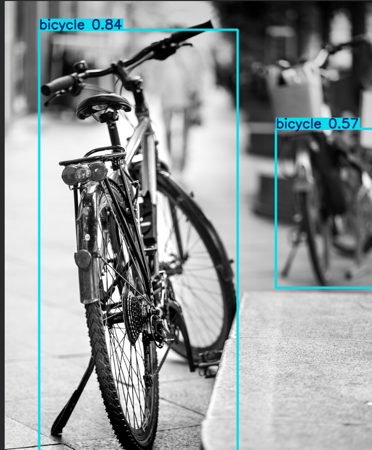

DESCRIPTION: A bicycle with a 0.84 camera angle, a 0.57 zoomed in photo of the bicycle, and a blue rectangle around the bicycle.

IMAGE: Screenshot 2026-10-23 185538 (1).png


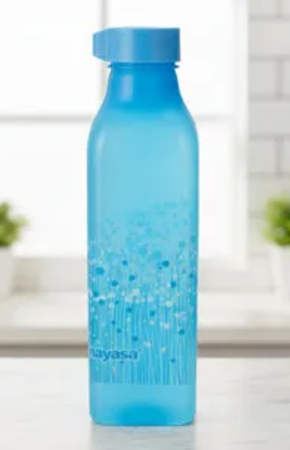

DESCRIPTION: A blue plastic bottle with a blue cap is on a white countertop. The bottle has a design on it that resembles a tree.

IMAGE: Screenshot 2026-10-23 185711 (1).png


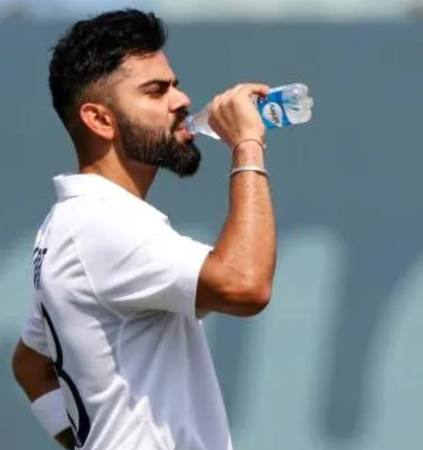

DESCRIPTION: A man in a white shirt is drinking from a blue water bottle. He is standing on a field with a blue sky in the background.

IMAGE: Screenshot 2026-10-23 185936.png


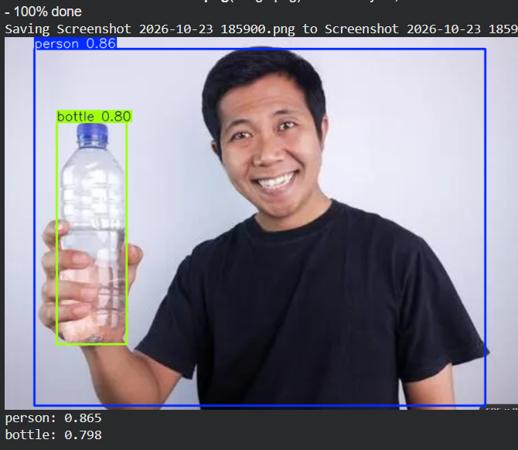

DESCRIPTION: Person wearing a black t-shirt, holding a plastic bottle with a blue cap, with a green box in the background.

IMAGE: Screenshot 2026-10-23 191813.png


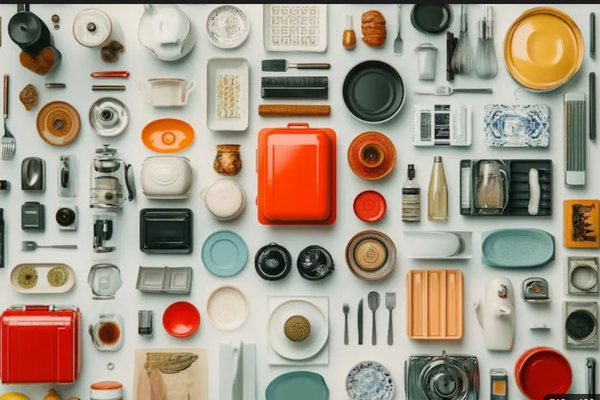

DESCRIPTION: The image is a collage of various kitchenware items arranged on a white surface. The items include plates, bowls, cups, utensils, and other kitchenware. The colors of the items vary, with some being white, orange, and black. The arrangement is random, with no discernible pattern or order. The objects are scattered across the surface, with no clear grouping or layout.

IMAGE: Screenshot 2026-10-23 195547.png


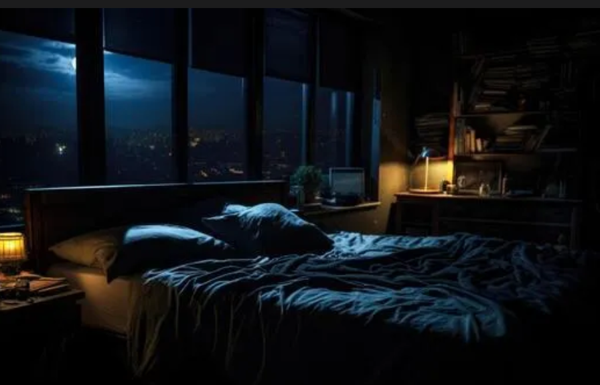

DESCRIPTION: The room is dark and has a large window that lets in a lot of light. There is a bed with a white comforter and two pillows. There is a nightstand with a lamp on it. There is a bookshelf with books on it.


In [54]:
test_folder = project / "images" / "evaluation"

for image_path in sorted(test_folder.iterdir()):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue

    with Image.open(image_path) as source:
        scene_image = source.convert("RGB")

    preview = scene_image.copy()
    preview.thumbnail((600, 450))

    print(f"\nIMAGE: {image_path.name}")
    display(preview)
    print("DESCRIPTION:", describe_scene(scene_image))